In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import Ridge, HuberRegressor

In [3]:
df = pd.read_csv(r'Q2.csv')
df.head()

,1,2,3,4,5,6,7,8,9,10,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000
0,13,29,44,55,61,72,200,96,112,120,...,21680,21692,21697,21705,21711,21729,21742,21746,21763,21777
1,-3980,-3883,-3832,0,-3839,-3788,-3695,-3663,-3669,0,...,7130,7150,7117,7023,7064,0,7027,6929,6954,6867
2,-3959,-4058,-4131,-4033,-4009,-3941,-3996,-4071,-3971,-4021,...,-254,-296,-303,0,-327,-274,-358,-278,-346,-299


In [7]:
# Extract the second row
row = df.iloc[1, :]
row

1      -3980.0
2      -3883.0
3      -3832.0
4          0.0
5      -3839.0
         ...  
1996       0.0
1997    7027.0
1998    6929.0
1999    6954.0
2000    6867.0
Name: 1, Length: 2000, dtype: float64

In [9]:
# Z-Score method
z_scores = (row - row.mean()) / row.std()
outliers_zscore = row[np.abs(z_scores) > 3]
outliers_zscore

Series([], Name: 1, dtype: float64)

In [11]:
# IQR method
Q1 = row.quantile(0.25)
Q3 = row.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = row[(row < lower_bound) | (row > upper_bound)]
outliers_iqr

Series([], Name: 1, dtype: float64)

Final coefficients with MSE: [-0.72876692  2.81854351]
Final coefficients with MAE: [2.43580500e-04 6.53603745e-01]


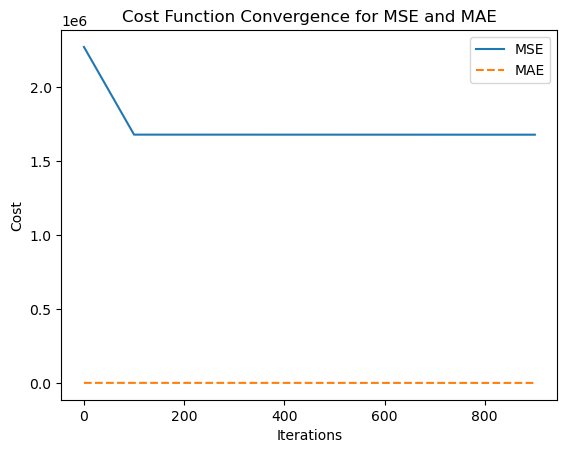

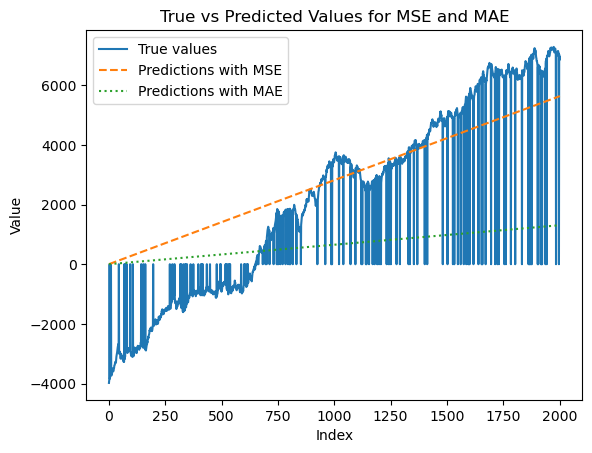

In [35]:
# Extract the second row (as the target data)
row2 = df.iloc[1, :].values

# Convert the row to a matrix of feature vectors (for simplicity, use X = [1, 2, 3, ..., N])
X = np.array([np.arange(1, len(row2) + 1)])

# Add a bias term to the feature matrix
X = np.vstack([np.ones(X.shape[1]), X])  # Adding a row of 1s for the bias term

# Define the true values (row2)
y = row2

# Initialize coefficients (beta) for the linear model
beta = np.zeros(X.shape[0])

# Define the learning rate and number of iterations
learning_rate = 0.000001  
iterations = 1000

# Define the Mean Squared Error (MSE) cost function
def compute_mse(X, y, beta):
    m = len(y)
    predictions = np.dot(X.T, beta)
    mse = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return mse

# Define the Mean Absolute Error (MAE) cost function
def compute_mae(X, y, beta):
    m = len(y)
    predictions = np.dot(X.T, beta)
    mae = (1 / m) * np.sum(np.abs(predictions - y))
    return mae

# Define the gradient descent algorithm for MSE
def gradient_descent_mse(X, y, beta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X.T, beta)
        errors = predictions - y
        gradients = (1 / m) * np.dot(X, errors)
        beta = beta - learning_rate * gradients

        # Store the cost for every 100 iterations to monitor the progress
        if i % 100 == 0:
            cost = compute_mse(X, y, beta)
            cost_history.append(cost)

    return beta, cost_history

# Define the gradient descent algorithm for MAE
def gradient_descent_mae(X, y, beta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X.T, beta)
        errors = predictions - y
        gradients = (1 / m) * np.dot(X, np.sign(errors))  # Using the sign of errors for MAE
        beta = beta - learning_rate * gradients

        # Store the cost for every 100 iterations to monitor the progress
        if i % 100 == 0:
            cost = compute_mae(X, y, beta)
            cost_history.append(cost)

    return beta, cost_history

# Train the model using gradient descent with MSE
beta_mse, cost_history_mse = gradient_descent_mse(X, y, beta, learning_rate, iterations)

# Train the model using gradient descent with MAE
beta_mae, cost_history_mae = gradient_descent_mae(X, y, beta, learning_rate, iterations)

# Output the final coefficients and plot the cost history
print("Final coefficients with MSE:", beta_mse)
print("Final coefficients with MAE:", beta_mae)

# Plot the cost history for both MSE and MAE
plt.plot(range(0, iterations, 100), cost_history_mse, label="MSE")
plt.plot(range(0, iterations, 100), cost_history_mae, label="MAE", linestyle='--')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()
plt.title('Cost Function Convergence for MSE and MAE')
plt.show()

# Use the final model to make predictions
predictions_mse = np.dot(X.T, beta_mse)
predictions_mae = np.dot(X.T, beta_mae)

# Display the predictions
plt.plot(np.arange(1, len(y) + 1), y, label="True values")
plt.plot(np.arange(1, len(y) + 1), predictions_mse, label="Predictions with MSE", linestyle='--')
plt.plot(np.arange(1, len(y) + 1), predictions_mae, label="Predictions with MAE", linestyle=':')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.title('True vs Predicted Values for MSE and MAE')
plt.show()


In [119]:
X = np.array([np.arange(1, len(row2) + 1)]).T 
y = row2

#  Linear Regression
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

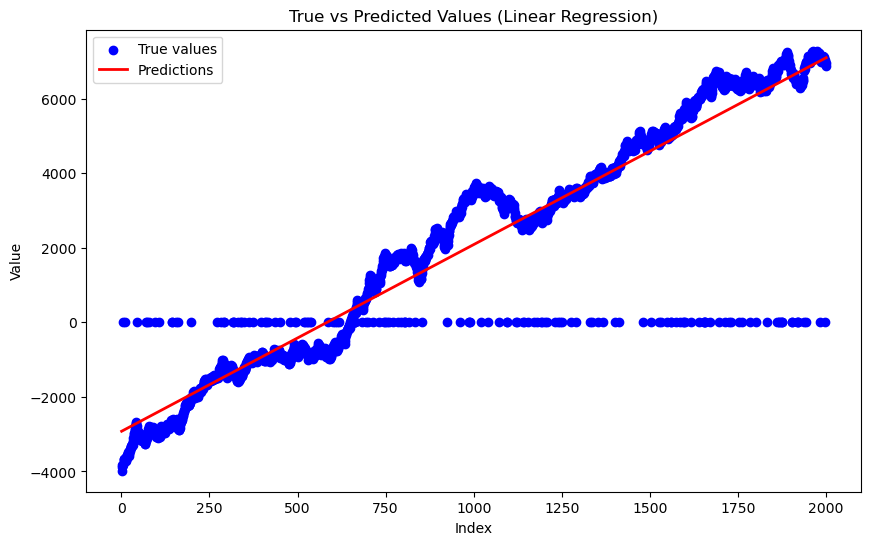

In [117]:
# رسم نتایج در فضای دو بعدی
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', label='True values')
plt.plot(X, y_pred, color='red', label='Predictions', linewidth=2)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('True vs Predicted Values (Linear Regression)')
plt.legend()
plt.show()

In [99]:
X = np.array([np.arange(1, len(row2) + 1)]).T  # تبدیل به شکل ماتریس (N, 1)
y = row2

# 1. Ridge Regression
ridge_model = Ridge(alpha=1.0)  # انتخاب مقدار alpha برای رگولاریزاسیون
ridge_model.fit(X, y)

# 2. Huber Regressor
huber_model = HuberRegressor()
huber_model.fit(X, y)

# پیش‌بینی با استفاده از هر دو مدل
y_pred_ridge = ridge_model.predict(X)
y_pred_huber = huber_model.predict(X)


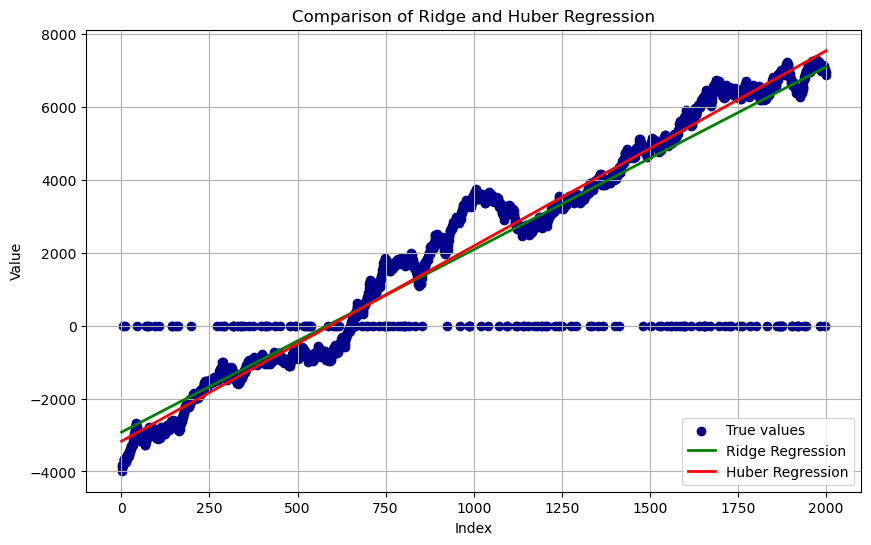

In [121]:
# رسم نتایج در فضای دو بعدی
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='DarkBlue', label='True values')

# رسم پیش‌بینی‌ها با مدل Ridge
plt.plot(X, y_pred_ridge, color='green', label='Ridge Regression', linewidth=2)

# رسم پیش‌بینی‌ها با مدل Huber
plt.plot(X, y_pred_huber, color='red', label='Huber Regression', linewidth=2)


plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Comparison of Ridge and Huber Regression')
plt.legend(loc='lower right')
plt.grid()
plt.show()

In [43]:
# چاپ پارامترهای هر مدل
print("Ridge Model Parameters:")
print(f"Alpha (regularization term): {ridge_model.alpha}")
print(f"Coefficients: {ridge_model.coef_}")
print(f"Intercept: {ridge_model.intercept_}")

print("\nHuber Model Parameters:")
print(f"Coefficients: {huber_model.coef_}")
print(f"Intercept: {huber_model.intercept_}")

Ridge Model Parameters:
Alpha (regularization term): 1.0
Coefficients: [5.0120074]
Intercept: -2926.077906935457

Huber Model Parameters:
Coefficients: [5.35803651]
Intercept: -3174.565093446588


In [59]:
# استفاده از الگوریتم Isolation Forest
row2_reshaped = row2.reshape(-1, 1)
iso_forest = IsolationForest(contamination=0.05)
outliers_iforest = iso_forest.fit_predict(row2_reshaped)

In [61]:
# شناسایی داده‌های پرت (برچسب -1 نشان‌دهنده داده‌های پرت است)
outliers = np.where(outliers_iforest == -1)[0]
outliers

array([   0,    1,    2,    4,    5,    6,    7,    8,   10,   11,   12,
         13,   14,   15,   16,   17,   18,   19,   20,   21,   22,   23,
         24,   25,   26,   27,   28,   29,   30,   31,   32,   52,   59,
         61,   62,   63,   64,   65,   66,   67,   69,   70,  141,  145,
        155,  156,  157,  170,  171,  172,  173,  174,  175,  176,  177,
        178,  179,  180,  181,  182,  183,  184,  186,  188,  189,  190,
        191,  192, 1885, 1886, 1887, 1888, 1889, 1890, 1891, 1948, 1955,
       1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967,
       1968, 1969, 1970, 1971, 1972, 1973, 1974, 1977, 1978, 1979, 1980,
       1991], dtype=int64)

In [63]:
row2_cleaned = np.delete(row2, outliers)
row2_cleaned

array([    0.,     0., -3105., ...,  6929.,  6954.,  6867.])

Final coefficients with MSE: [-0.6309616   2.96702293]


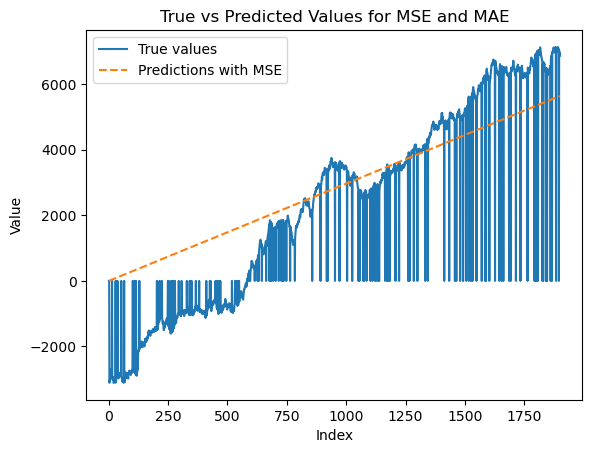

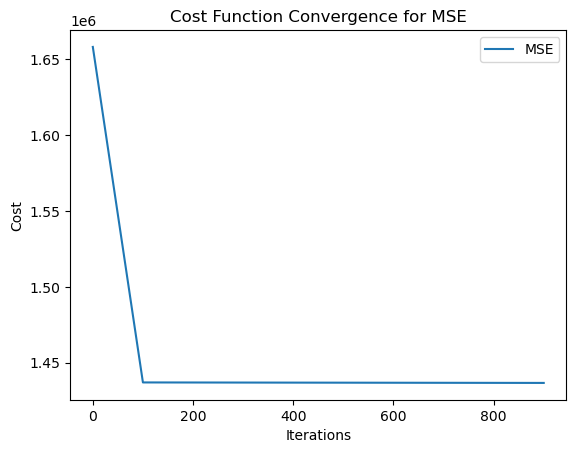

In [75]:
# Convert the row to a matrix of feature vectors (for simplicity, use X = [1, 2, 3, ..., N])
X = np.array([np.arange(1, len(row2_cleaned) + 1)])

# Add a bias term to the feature matrix
X = np.vstack([np.ones(X.shape[1]), X])  # Adding a row of 1s for the bias term

# Define the true values (row2)
y = row2_cleaned

# Initialize coefficients (beta) for the linear model
beta = np.zeros(X.shape[0])

# Define the learning rate and number of iterations
learning_rate = 0.000001  
iterations = 1000

# Define the Mean Squared Error (MSE) cost function
def compute_mse(X, y, beta):
    m = len(y)
    predictions = np.dot(X.T, beta)
    mse = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return mse
# Define the gradient descent algorithm for MSE
def gradient_descent_mse(X, y, beta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X.T, beta)
        errors = predictions - y
        gradients = (1 / m) * np.dot(X, errors)
        beta = beta - learning_rate * gradients

        # Store the cost for every 100 iterations to monitor the progress
        if i % 100 == 0:
            cost = compute_mse(X, y, beta)
            cost_history.append(cost)

    return beta, cost_history


# Train the model using gradient descent with MSE
beta_mse, cost_history_mse = gradient_descent_mse(X, y, beta, learning_rate, iterations)

# Output the final coefficients and plot the cost history
print("Final coefficients with MSE:", beta_mse)

predictions_mse = np.dot(X.T, beta_mse)


# Display the predictions
plt.plot(np.arange(1, len(y) + 1), y, label="True values")
plt.plot(np.arange(1, len(y) + 1), predictions_mse, label="Predictions with MSE", linestyle='--')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.title('True vs Predicted Values for MSE and MAE')
plt.show()


# Plot the cost history for  MSE  
plt.plot(range(0, iterations, 100), cost_history_mse, label="MSE")
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()
plt.title('Cost Function Convergence for MSE')
plt.show()

Final coefficients with MAE: [-5.70721053e-04  3.27053457e+00]


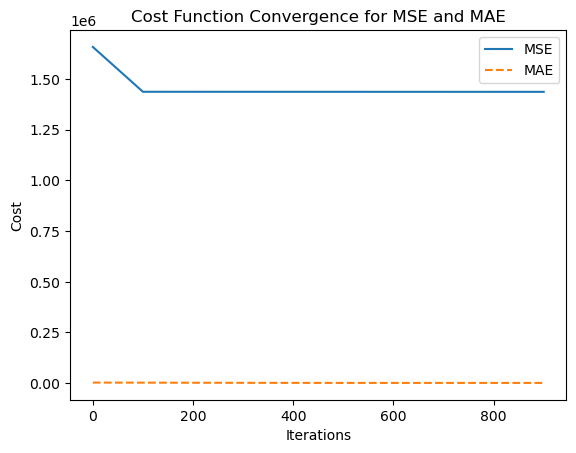

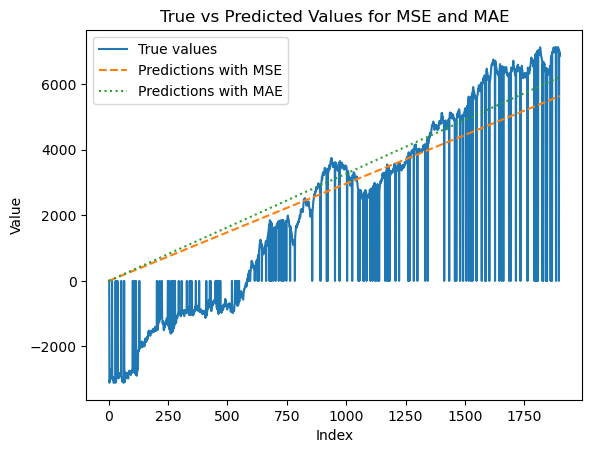

In [73]:
# Convert the row to a matrix of feature vectors (for simplicity, use X = [1, 2, 3, ..., N])
X = np.array([np.arange(1, len(row2_cleaned) + 1)])

# Add a bias term to the feature matrix
X = np.vstack([np.ones(X.shape[1]), X])  # Adding a row of 1s for the bias term

# Define the true values (row2)
y = row2_cleaned

# Initialize coefficients (beta) for the linear model
beta = np.zeros(X.shape[0])

# Define the learning rate and number of iterations
learning_rate = 0.00001  
iterations = 1000

# Define the Mean Absolute Error (MAE) cost function
def compute_mae(X, y, beta):
    m = len(y)
    predictions = np.dot(X.T, beta)
    mae = (1 / m) * np.sum(np.abs(predictions - y))
    return mae


# Define the gradient descent algorithm for MAE
def gradient_descent_mae(X, y, beta, learning_rate, iterations):
    m = len(y)
    cost_history = []

    for i in range(iterations):
        predictions = np.dot(X.T, beta)
        errors = predictions - y
        gradients = (1 / m) * np.dot(X, np.sign(errors))  # Using the sign of errors for MAE
        beta = beta - learning_rate * gradients

        # Store the cost for every 100 iterations to monitor the progress
        if i % 100 == 0:
            cost = compute_mae(X, y, beta)
            cost_history.append(cost)

    return beta, cost_history



# Train the model using gradient descent with MAE
beta_mae, cost_history_mae = gradient_descent_mae(X, y, beta, learning_rate, iterations)


print("Final coefficients with MAE:", beta_mae)

# Plot the cost history for both MSE and MAE
plt.plot(range(0, iterations, 100), cost_history_mse, label="MSE")
plt.plot(range(0, iterations, 100), cost_history_mae, label="MAE", linestyle='--')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.legend()
plt.title('Cost Function Convergence for MSE and MAE')
plt.show()

# Use the final model to make predictions

predictions_mae = np.dot(X.T, beta_mae)

# Display the predictions
plt.plot(np.arange(1, len(y) + 1), y, label="True values")
plt.plot(np.arange(1, len(y) + 1), predictions_mse, label="Predictions with MSE", linestyle='--')
plt.plot(np.arange(1, len(y) + 1), predictions_mae, label="Predictions with MAE", linestyle=':')
plt.xlabel('Index')
plt.ylabel('Value')
plt.legend()
plt.title('True vs Predicted Values for MSE and MAE')
plt.show()

In [89]:
X2 = np.array([np.arange(1, len(row2_cleaned) + 1)]).T 
y2 = row2_cleaned

#Linear Regression
model = LinearRegression()
model.fit(X2, y2)
y_pred2 = model.predict(X2)

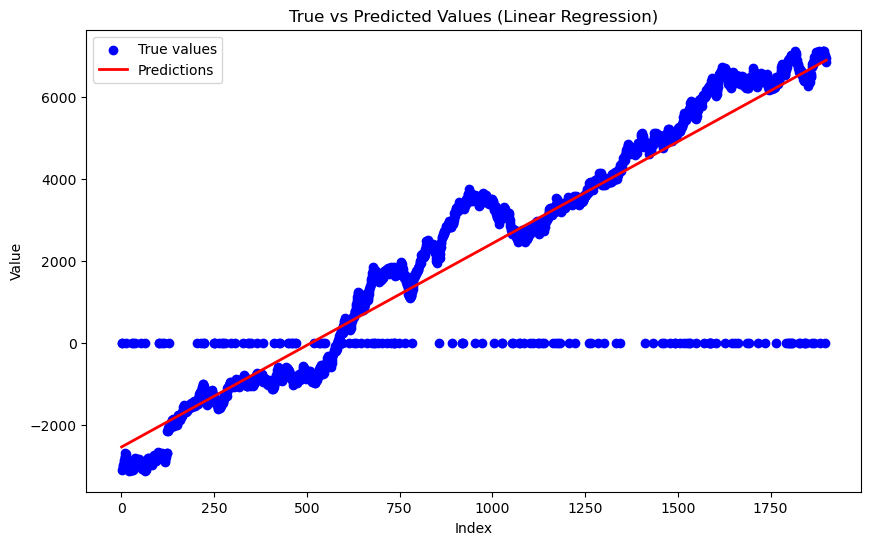

In [91]:
# رسم نتایج در فضای دو بعدی
plt.figure(figsize=(10, 6))
plt.scatter(X2, y2, color='blue', label='True values')
plt.plot(X2, y_pred2, color='red', label='Predictions', linewidth=2)
plt.xlabel('Index')
plt.ylabel('Value')
plt.title('True vs Predicted Values (Linear Regression)')
plt.legend()
plt.show()

In [109]:
X2 = np.array([np.arange(1, len(row2_cleaned) + 1)]).T 
y2 = row2_cleaned

# 1. آموزش مدل Ridge Regression
ridge_model2 = Ridge(alpha=1.0)  # انتخاب مقدار alpha برای رگولاریزاسیون
ridge_model2.fit(X2, y2)

# 2. آموزش مدل Huber Regressor
huber_model2 = HuberRegressor()
huber_model2.fit(X2, y2)

# پیش‌بینی با استفاده از هر دو مدل
y_pred_ridge2 = ridge_model2.predict(X2)
y_pred_huber2 = huber_model2.predict(X2)

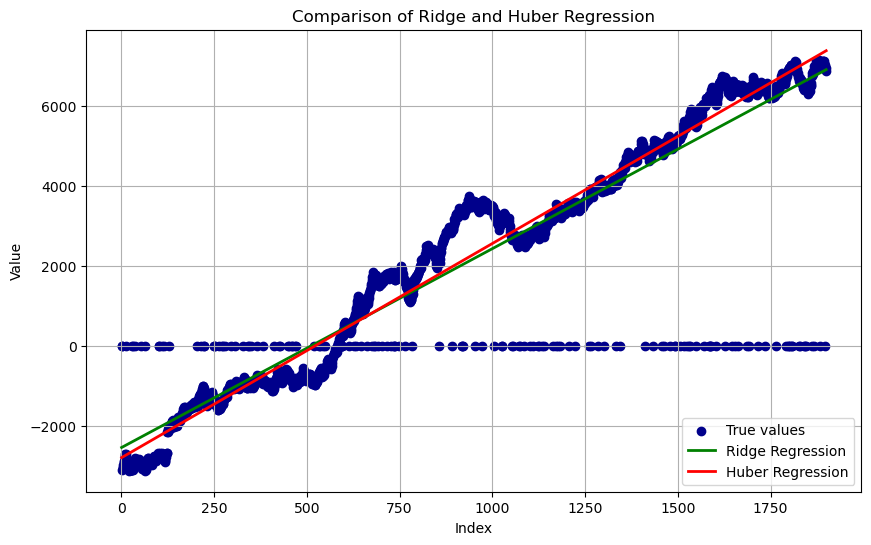

In [111]:
# رسم نتایج در فضای دو بعدی
plt.figure(figsize=(10, 6))
plt.scatter(X2, y2, color='DarkBlue', label='True values')

# رسم با مدل Ridge
plt.plot(X2, y_pred_ridge2, color='green', label='Ridge Regression', linewidth=2)

# رسم با مدل Huber
plt.plot(X2, y_pred_huber2, color='red', label='Huber Regression', linewidth=2)

plt.xlabel('Index')
plt.ylabel('Value')
plt.title('Comparison of Ridge and Huber Regression')
plt.legend(loc='lower right')
plt.grid()
plt.show()